# Customer & Revenue Analytics: Statistical Business Analysis

## 1. Аудит исходных данных

На первом этапе проводится первичный аудит датасета Online Retail II.
Датасет содержит транзакции британского онлайн-магазина за период
с декабря 2009 года по декабрь 2011 года.
Цель этапа — оценить структуру и качество исходных данных перед
проведением статистического и бизнес-анализа.

In [1]:
import pandas as pd
import numpy as np
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
FILE_PATH = "../data/raw/online_retail_II.xlsx"
df_2009_2010 = pd.read_excel(
    FILE_PATH,
    sheet_name="Year 2009-2010")
df_2010_2011 = pd.read_excel(
    FILE_PATH,
    sheet_name="Year 2010-2011")
print(f"Размер данных за 2009-2010: {df_2009_2010.shape}")
print(f"Размер данных за 2010-2011: {df_2010_2011.shape}")

Размер данных за 2009-2010: (525461, 8)
Размер данных за 2010-2011: (541910, 8)


### Структура данных

В исходном файле представлены два периода наблюдений.
Основные признаки:
- Invoice — номер заказа;
- StockCode — код товара;
- Description — описание товара;
- Quantity — количество единиц товара;
- InvoiceDate — дата и время заказа;
- Price — цена единицы товара;
- Customer ID — идентификатор клиента;
- Country — страна клиента.

In [66]:
df_2009_2010.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


### Проверка пропусков


In [67]:
missing_2009_2010 = df_2009_2010.isna().sum()
display(
    missing_2009_2010
    .to_frame("Количество пропусков")
    .assign(
        Доля_пропусков=lambda x:
        (x["Количество пропусков"] / len(df_2009_2010) * 100).round(2)
    ))

,Количество пропусков,Доля_пропусков
Invoice,0,0.00
StockCode,0,0.00
Description,2928,0.56
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,107927,20.54
Country,0,0.00


### Проверка дубликатов за 2009-2010

In [4]:
duplicates = df_2009_2010.duplicated().sum()
print(f"Количество полных дубликатов: {duplicates}")

Количество полных дубликатов: 6865


## 2. Первичная оценка качества данных

Посмотрел на данные — сразу видно три вещи:
- у части транзакций нет id клиента;
- у небольшой части товаров не заполнено описание;
- есть полные дубли строк.

Пока ничего не удаляю. Сначала надо разобраться, что из этого реально мешает анализу, а что просто особенность данных.

### Проверка качества данных за 2010–2011


In [5]:
missing_2010_2011 = df_2010_2011.isna().sum()

display(
    missing_2010_2011
    .to_frame("Количество пропусков")
    .assign(
        Доля_пропусков=lambda x:
        (x["Количество пропусков"] / len(df_2010_2011) * 100).round(2)
    ))
duplicates_2010_2011 = df_2010_2011.duplicated().sum()
print(f"Количество полных дубликатов: {duplicates_2010_2011}")

,Количество пропусков,Доля_пропусков
Invoice,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,135080,24.93
Country,0,0.00


Количество полных дубликатов: 5268


## 3. Сравнение качества данных по периодам

По обоим периодам картина с пропусками примерно одинаковая.
Самое заметное — это Customer ID: его нет у 20,54% строк за 2009–2010 и у 24,93% за 2010–2011.
Всё остальное на месте: id заказов, id товаров, даты, цены и количество заполнены полностью.
Description пропущен гораздо реже — меньше 1% в каждом из периодов.
Ещё есть полные дубли строк. Их немного относительно всего объёма, но перед тем как считать статистику, стоит проверить, не искажают ли они транзакционные показатели.

## 4. Объединение данных

Для дальнейшего анализа объединим оба временных периода в единую
таблицу.
После объединения проверим общий размер датасета и временной диапазон
наблюдений.

In [6]:
df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)
print(f"Общий размер датасета: {df.shape}")
print(f"\nМинимальная дата: {df['InvoiceDate'].min()}")
print(f"Максимальная дата: {df['InvoiceDate'].max()}")

Общий размер датасета: (1067371, 8)

Минимальная дата: 2009-12-01 07:45:00
Максимальная дата: 2011-12-09 12:50:00


In [7]:
display(df.head())
display(df.tail())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


## 5. Проверка транзакций на аномальные значения

Перед расчётом выручки надо посмотреть, всё ли хорошо с транзакциями.

Смотрим на:
- отменённые заказы
- отрицательный Quantity
- нулевой и отрицательный Price

Удалять сразу не буду — отрицательное количество может быть возвратом. Сначала посмотрю, сколько таких строк и что они из себя представляют.

In [8]:
cancelled = df["Invoice"].astype(str).str.startswith("C")
print(f"Отменённых заказов: {cancelled.sum():,}")
print(f"Доля строк с отменёнными заказами: {cancelled.mean() * 100:.2f}%")

Отменённых заказов: 19,494
Доля строк с отменёнными заказами: 1.83%


In [9]:
negative_quantity = (df["Quantity"] < 0).sum()
zero_quantity = (df["Quantity"] == 0).sum()
print(f"Строк с отрицательным Quantity: {negative_quantity:,}")
print(f"Строк с Quantity = 0: {zero_quantity:,}")

Строк с отрицательным Quantity: 22,950
Строк с Quantity = 0: 0


In [10]:
negative_price = (df["Price"] < 0).sum()
zero_price = (df["Price"] == 0).sum()
print(f"Строк с отрицательной Price: {negative_price:,}")
print(f"Строк с Price = 0: {zero_price:,}")

Строк с отрицательной Price: 5
Строк с Price = 0: 6,202


 Связь отменённых заказов и отрицательного Quantity

In [11]:
comparison = pd.crosstab(
    cancelled,
    df["Quantity"] < 0,
    margins=True)
display(comparison)

Quantity,False,True,All
Invoice,,,
False,1044420,3457,1047877
True,1,19493,19494
All,1044421,22950,1067371


## 6. Анализ отрицательных значений Quantity

Нашла 22 950 строк с отрицательным Quantity — это примерно 2,15% от всех наблюдений.
Большая часть приходится на отменённые заказы: 19 493 строки, где сразу и Quantity отрицательный, и InvoiceNo начинается с `C`.

Но остаётся 3 457 строк с отрицательным Quantity, которые к таким заказам не относятся. То есть просто так их удалять нельзя — надо сначала разобраться, что это вообще за строки.

In [12]:
negative_non_cancelled = df[
    (df["Quantity"] < 0) &
    (~df["Invoice"].astype(str).str.startswith("C"))
]
print(f"Количество отрицательных Quantity без признака отмены: {len(negative_non_cancelled):,}")
display(
    negative_non_cancelled[
        ["Invoice", "StockCode", "Description",
         "Quantity", "InvoiceDate", "Price", "Customer ID", "Country"]
    ].head(20))

Количество отрицательных Quantity без признака отмены: 3,457


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


In [13]:
negative_quantity_stats = df.loc[
    df["Quantity"] < 0, "Quantity"
].describe()
display(negative_quantity_stats)

count    22950.000000
mean       -46.365054
std        788.250496
min     -80995.000000
25%        -11.000000
50%         -2.000000
75%         -1.000000
max         -1.000000
Name: Quantity, dtype: float64

## 7. Проверка нулевой и отрицательной цены

Нашла 6 202 строки с Price = 0 и 5 строк с отрицательной ценой.

Нулевая цена — это не обязательно ошибка. Товар мог идти бесплатно, как промо, или это вообще какая-то отдельная операция.
Так что прежде чем их убирать, надо посмотреть, что это за товары и в каких заказах они встречаются.

## 8. Интерпретация отрицательных Quantity
Дополнительно проверила отрицательные Quantity, которые не связаны с отменёнными заказами — у них структура другая.
Для таких строк характерно:
- нет Customer ID
- Price = 0
- крупные отрицательные значения Quantity.
Похоже, что это внутренние корректировки остатков, потери или повреждения, а не покупки клиентов.
Значит, в расчёт клиентской выручки и поведения покупателей их брать не надо.
Но из датасета я их не удаляю — исходные данные должны оставаться воспроизводимыми.

In [14]:
df["IsCancelled"] = df["Invoice"].astype(str).str.startswith("C")
df["IsNegativeQuantity"] = df["Quantity"] < 0
df["IsInternalAdjustment"] = (
    (df["Quantity"] < 0) &
    (~df["IsCancelled"]) &
    (df["Price"] == 0)
)
print(
    "Внутренних корректировок:",
    df["IsInternalAdjustment"].sum())

Внутренних корректировок: 3457


In [15]:
sales_mask = (
    (~df["IsCancelled"]) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
)
print(f"Всего строк: {len(df):,}")
print(f"Строк для анализа продаж: {sales_mask.sum():,}")
print(f"Исключено из анализа продаж: {(~sales_mask).sum():,}")

Всего строк: 1,067,371
Строк для анализа продаж: 1,041,670
Исключено из анализа продаж: 25,701


## 9. Анализ нулевой цены
В данных 6 202 строки с Price = 0.
Нулевая цена — это не обязательно ошибка: такие строки могут быть бесплатными товарами, промо или внутренними корректировками.
Поэтому перед исключением надо посмотреть, какие товары и операции в них встречаются.

In [16]:
zero_price = df[df["Price"] == 0].copy()
print(f"Количество строк с Price = 0: {len(zero_price):,}")
print(f"Уникальных товаров: {zero_price['StockCode'].nunique():,}")
print(f"Уникальных заказов: {zero_price['Invoice'].nunique():,}")
print(f"Уникальных клиентов: {zero_price['Customer ID'].nunique():,}")

Количество строк с Price = 0: 6,202
Уникальных товаров: 2,971
Уникальных заказов: 5,379
Уникальных клиентов: 51


In [17]:
display(
    zero_price["Description"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("Количество"))

,Количество
Description,
NaN,4382
check,162
?,92
damages,84
damaged,81
found,28
missing,27
sold as set on dotcom,20
Damaged,17


In [18]:
display(
    zero_price["Quantity"].describe())

count     6202.000000
mean       -51.729442
std        632.376662
min      -9600.000000
25%        -32.000000
50%         -2.000000
75%          3.000000
max      12540.000000
Name: Quantity, dtype: float64

## 10. Проверка отрицательной цены

Отрицательная цена встречается только в нескольких наблюдениях,
поэтому рассмотрим их отдельно.

In [19]:
display(
    df[df["Price"] < 0])

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,IsNegativeQuantity,IsInternalAdjustment
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,False,False,False
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,False,False,False
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,False,False,False
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,False,False,False
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,False,False,False


## 11. Интерпретация нулевой и отрицательной цены
Проверка строк с Price = 0 показала, что они сильно отличаются от обычных продаж.
Там встречаются служебные описания вроде check, damages, damaged, adjustment, missing, smashed и подобное. Во многих таких строках нет Customer ID.
Значит, строки с нулевой ценой нельзя считать обычными продажами и использовать при расчёте клиентской выручки.
Отрицательная цена есть только в пяти наблюдениях. Все они связаны с Adjust bad debt и покупателя не имеют. Их тоже исключаю из расчёта выручки.
Сам датасет при этом не трогаю, строки не удаляю. Фильтрация будет только при формировании выборки для анализа продаж.

## 12. Формирование выборки продаж
Для анализа клиентского поведения и выручки оставляю транзакции, которые соответствуют обычным продажам:
- заказ не отменён
- количество товара положительное
- цена товара положительная
Так я отделяю клиентские продажи от возвратов, внутренних корректировок, списаний и прочих служебных операций.

In [20]:
sales_mask = (
    (~df["IsCancelled"]) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
)
sales_df = df.loc[sales_mask].copy()
print(f"Исходный датасет: {len(df):,} строк")
print(f"Выборка продаж: {len(sales_df):,} строк")
print(f"Исключено: {len(df) - len(sales_df):,} строк")
print(f"Доля сохранённых строк: {len(sales_df) / len(df) * 100:.2f}%")

Исходный датасет: 1,067,371 строк
Выборка продаж: 1,041,670 строк
Исключено: 25,701 строк
Доля сохранённых строк: 97.59%


In [21]:
print("Отрицательный Quantity:", (sales_df["Quantity"] < 0).sum())
print("Нулевая Quantity:", (sales_df["Quantity"] == 0).sum())
print("Нулевая Price:", (sales_df["Price"] == 0).sum())
print("Отрицательная Price:", (sales_df["Price"] < 0).sum())

Отрицательный Quantity: 0
Нулевая Quantity: 0
Нулевая Price: 0
Отрицательная Price: 0


## 13. Формирование итоговой выборки для бизнес-анализа
Для дальнейшего анализа беру только реальные продажи:
- счёт не отменён
- Quantity > 0
- Price > 0
Из исходных 1 067 371 строки получилась выборка из 1 041 670 продаж. То есть для бизнес-анализа осталось 97,59% наблюдений.
Исключённые записи из исходного датасета не удаляла — они просто не попали в аналитическую выборку, потому что там отмены, возвраты, внутренние корректировки или некорректная цена.

## 14. Базовые бизнес-метрики
На этом этапе считаю основные показатели продаж, чтобы понять масштаб бизнеса и активность клиентов:
- общая выручка
- количество заказов
- количество уникальных клиентов
- количество уникальных товаров
- средний чек
- среднее количество товаров в заказе
- период анализа

In [22]:
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["Price"]
total_revenue = sales_df["Revenue"].sum()
orders_count = sales_df["Invoice"].nunique()
customers_count = sales_df["Customer ID"].nunique()
products_count = sales_df["StockCode"].nunique()
average_order_value = (
    sales_df.groupby("Invoice")["Revenue"].sum().mean())
avg_items_per_order = (
    sales_df.groupby("Invoice")["Quantity"].sum().mean())
analysis_start = sales_df["InvoiceDate"].min()
analysis_end = sales_df["InvoiceDate"].max()
print(f"Общая выручка: £{total_revenue:,.2f}")
print(f"Количество заказов: {orders_count:,}")
print(f"Количество уникальных клиентов: {customers_count:,}")
print(f"Количество уникальных товаров: {products_count:,}")
print(f"Средний чек: £{average_order_value:,.2f}")
print(f"Среднее количество товаров в заказе: {avg_items_per_order:.2f}")
print(f"Период анализа: {analysis_start} — {analysis_end}")

Общая выручка: £20,972,594.57
Количество заказов: 40,077
Количество уникальных клиентов: 5,878
Количество уникальных товаров: 4,917
Средний чек: £523.31
Среднее количество товаров в заказе: 284.96
Период анализа: 2009-12-01 07:45:00 — 2011-12-09 12:50:00


### Результаты
За весь период анализа:
- выручка составила **£20.97 млн**
- совершено **40 077 заказов**
- количество идентифицированных клиентов — **5 878**
- в продажах представлено **4 917 уникальных товаров**
- средний чек составил **£523.31**
- среднее количество единиц товара на заказ — **284.96**
Эти показатели дают общее представление о масштабе продаж и дальше будут базовыми метриками для анализа клиентского поведения, динамики выручки и статистических гипотез.

## 15. Динамика выручки во времени

Для оценки изменения бизнес-показателей во времени рассмотрим месячную динамику выручки.
Анализ позволит определить периоды роста и снижения продаж, а также выявить возможную сезонность.

In [23]:
monthly_revenue = (
    sales_df
    .assign(Month=sales_df["InvoiceDate"].dt.to_period("M"))
    .groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)
monthly_revenue["Month"] = monthly_revenue["Month"].astype(str)
monthly_revenue

,Month,Revenue
0,2009-12,825685.760
1,2010-01,652708.502
2,2010-02,553339.736
3,2010-03,833570.131
4,2010-04,681528.992
5,2010-05,659858.860
6,2010-06,752270.140
7,2010-07,650712.940
8,2010-08,697274.910
9,2010-09,924333.011


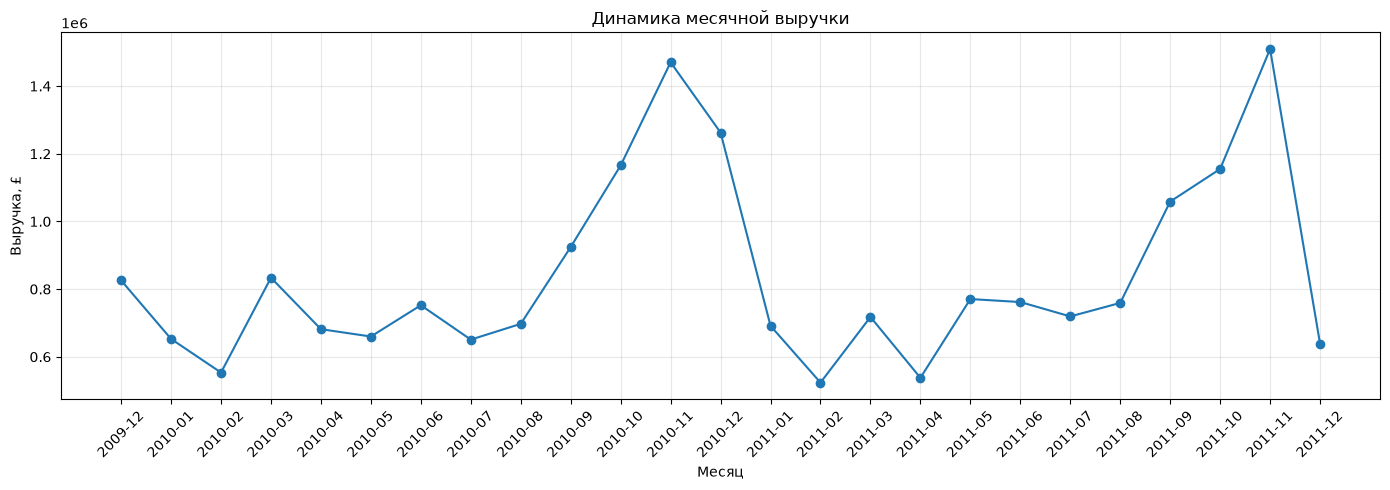

In [24]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["Revenue"],
    marker="o"
)
plt.title("Динамика месячной выручки")
plt.xlabel("Месяц")
plt.ylabel("Выручка, £")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Сравнение выручки по месяцам

Чтобы оценить изменение продаж между годами, сравним выручку за одинаковые месяцы 2010 и 2011 годов.
Такой подход позволяет увидеть месяцы с наиболее сильным ростом или снижением выручки и отделить сезонные колебания от изменения общего уровня продаж.

In [25]:
monthly_comparison = (
    sales_df
    .assign(
        Year=sales_df["InvoiceDate"].dt.year,
        Month=sales_df["InvoiceDate"].dt.month)
    .query("Year in [2010, 2011]")
    .groupby(["Month", "Year"])["Revenue"]
    .sum()
    .unstack("Year"))
monthly_comparison = monthly_comparison.rename(
    columns={
        2010: "Revenue_2010",
        2011: "Revenue_2011"
    })
monthly_comparison["YoY_change_%"] = (
    (monthly_comparison["Revenue_2011"] - monthly_comparison["Revenue_2010"])
    / monthly_comparison["Revenue_2010"]
    * 100)
monthly_comparison

Year,Revenue_2010,Revenue_2011,YoY_change_%
Month,,,
1,652708.502,691364.560,5.922408
2,553339.736,523631.890,-5.368826
3,833570.131,717639.360,-13.907741
4,681528.992,537808.621,-21.087932
5,659858.860,770536.020,16.772854
6,752270.140,761739.900,1.258824
7,650712.940,719221.191,10.528183
8,697274.910,759138.380,8.872178
9,924333.011,1058590.172,14.524761


In [26]:
yoy_comparison = monthly_comparison.drop(index=12)
yoy_comparison.sort_values("YoY_change_%", ascending=False)

Year,Revenue_2010,Revenue_2011,YoY_change_%
Month,,,
5,659858.860,770536.020,16.772854
9,924333.011,1058590.172,14.524761
7,650712.940,719221.191,10.528183
8,697274.910,759138.380,8.872178
1,652708.502,691364.560,5.922408
11,1470272.482,1509496.330,2.667794
6,752270.140,761739.900,1.258824
10,1165483.910,1154979.300,-0.901309
2,553339.736,523631.890,-5.368826


### Наиболее значимые изменения

Для выявления месяцев с наиболее сильной динамикой определим максимальный рост и максимальное снижение выручки год к году.

In [27]:
best_month = yoy_comparison["YoY_change_%"].idxmax()
worst_month = yoy_comparison["YoY_change_%"].idxmin()
best_change = yoy_comparison.loc[best_month, "YoY_change_%"]
worst_change = yoy_comparison.loc[worst_month, "YoY_change_%"]
print(
    f"Наибольший рост выручки: месяц {best_month}, "
    f"{best_change:.2f}%")
print(
    f"Наибольшее снижение выручки: месяц {worst_month}, "
    f"{worst_change:.2f}%")

Наибольший рост выручки: месяц 5, 16.77%
Наибольшее снижение выручки: месяц 4, -21.09%


## 17. Анализ новых и повторных клиентов
Чтобы оценить клиентское поведение, разделю покупателей на новых и повторных.
Клиент считается новым в том месяце, когда сделал первую покупку. Если он покупает и в следующие месяцы, то он уже повторный.
Такой подход показывает удержание клиентской базы и то, насколько выручка зависит от повторных покупок.

In [28]:
customer_month = (
    sales_df
    .assign(
        Year=sales_df["InvoiceDate"].dt.year,
        Month=sales_df["InvoiceDate"].dt.to_period("M")
    )
    .groupby(["Customer ID", "Month"])
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("Invoice", "nunique") )
    .reset_index())
customer_month.head()

,Customer ID,Month,Revenue,Orders
0,12346.0,2009-12,113.50,5
1,12346.0,2010-01,90.00,4
2,12346.0,2010-03,27.05,1
3,12346.0,2010-06,142.31,1
4,12346.0,2011-01,77183.60,1


In [29]:
first_purchase = (
    customer_month
    .groupby("Customer ID")["Month"]
    .min()
    .rename("FirstPurchaseMonth"))
customer_month = customer_month.merge(
    first_purchase,
    on="Customer ID",
    how="left")
customer_month["CustomerType"] = np.where(
    customer_month["Month"] == customer_month["FirstPurchaseMonth"],
    "New",
    "Returning")
customer_month.head()

,Customer ID,Month,Revenue,Orders,FirstPurchaseMonth,CustomerType
0,12346.0,2009-12,113.50,5,2009-12,New
1,12346.0,2010-01,90.00,4,2009-12,Returning
2,12346.0,2010-03,27.05,1,2009-12,Returning
3,12346.0,2010-06,142.31,1,2009-12,Returning
4,12346.0,2011-01,77183.60,1,2009-12,Returning


In [30]:
customer_month_summary = (
    customer_month
    .groupby(["Month", "CustomerType"])
    .agg(
        Customers=("Customer ID", "nunique"),
        Revenue=("Revenue", "sum"),
        Orders=("Orders", "sum"))
    .reset_index())
customer_month_summary

,Month,CustomerType,Customers,Revenue,Orders
0,2009-12,New,955,686654.160,1512
1,2010-01,New,383,161893.491,442
2,2010-01,Returning,337,395425.571,569
3,2010-02,New,374,170434.884,441
4,2010-02,Returning,398,335936.182,663
5,2010-03,New,443,235467.061,529
6,2010-03,Returning,614,464141.930,995
7,2010-04,New,294,125100.731,325
8,2010-04,Returning,648,469508.461,1004
9,2010-05,New,254,110770.000,285


In [31]:
customer_analysis = customer_month_summary.copy()
customer_analysis["Revenue_per_Customer"] = (
    customer_analysis["Revenue"] / customer_analysis["Customers"])
customer_analysis["Orders_per_Customer"] = (
    customer_analysis["Orders"] / customer_analysis["Customers"])
customer_analysis

,Month,CustomerType,Customers,Revenue,Orders,Revenue_per_Customer,Orders_per_Customer
0,2009-12,New,955,686654.160,1512,719.009592,1.583246
1,2010-01,New,383,161893.491,442,422.698410,1.154047
2,2010-01,Returning,337,395425.571,569,1173.369647,1.688427
3,2010-02,New,374,170434.884,441,455.708246,1.179144
4,2010-02,Returning,398,335936.182,663,844.060759,1.665829
5,2010-03,New,443,235467.061,529,531.528354,1.194131
6,2010-03,Returning,614,464141.930,995,755.931482,1.620521
7,2010-04,New,294,125100.731,325,425.512690,1.105442
8,2010-04,Returning,648,469508.461,1004,724.550094,1.549383
9,2010-05,New,254,110770.000,285,436.102362,1.122047


In [32]:
monthly_totals = (
    customer_analysis
    .groupby("Month")
    .agg(
        Total_Customers=("Customers", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("Orders", "sum"))
    .reset_index())
customer_analysis = customer_analysis.merge(
    monthly_totals,
    on="Month",
    how="left")
customer_analysis["Customer_Share"] = (
    customer_analysis["Customers"]
    / customer_analysis["Total_Customers"] * 100)
customer_analysis["Revenue_Share"] = (
    customer_analysis["Revenue"]
    / customer_analysis["Total_Revenue"] * 100)
customer_analysis

,Month,CustomerType,Customers,Revenue,Orders,Revenue_per_Customer,Orders_per_Customer,Total_Customers,Total_Revenue,Total_Orders,Customer_Share,Revenue_Share
0,2009-12,New,955,686654.160,1512,719.009592,1.583246,955,686654.160,1512,100.000000,100.000000
1,2010-01,New,383,161893.491,442,422.698410,1.154047,720,557319.062,1011,53.194444,29.048619
2,2010-01,Returning,337,395425.571,569,1173.369647,1.688427,720,557319.062,1011,46.805556,70.951381
3,2010-02,New,374,170434.884,441,455.708246,1.179144,772,506371.066,1104,48.445596,33.658101
4,2010-02,Returning,398,335936.182,663,844.060759,1.665829,772,506371.066,1104,51.554404,66.341899
5,2010-03,New,443,235467.061,529,531.528354,1.194131,1057,699608.991,1524,41.911069,33.656952
6,2010-03,Returning,614,464141.930,995,755.931482,1.620521,1057,699608.991,1524,58.088931,66.343048
7,2010-04,New,294,125100.731,325,425.512690,1.105442,942,594609.192,1329,31.210191,21.039152
8,2010-04,Returning,648,469508.461,1004,724.550094,1.549383,942,594609.192,1329,68.789809,78.960848
9,2010-05,New,254,110770.000,285,436.102362,1.122047,966,599985.790,1377,26.293996,18.462104


In [33]:
customer_analysis["Revenue_vs_Customer_Gap"] = (
    customer_analysis["Revenue_Share"]
    - customer_analysis["Customer_Share"])
customer_analysis[
    ["Month", "CustomerType", "Customer_Share",
     "Revenue_Share", "Revenue_vs_Customer_Gap"]]

,Month,CustomerType,Customer_Share,Revenue_Share,Revenue_vs_Customer_Gap
0,2009-12,New,100.000000,100.000000,0.000000
1,2010-01,New,53.194444,29.048619,-24.145825
2,2010-01,Returning,46.805556,70.951381,24.145825
3,2010-02,New,48.445596,33.658101,-14.787495
4,2010-02,Returning,51.554404,66.341899,14.787495
5,2010-03,New,41.911069,33.656952,-8.254117
6,2010-03,Returning,58.088931,66.343048,8.254117
7,2010-04,New,31.210191,21.039152,-10.171039
8,2010-04,Returning,68.789809,78.960848,10.171039
9,2010-05,New,26.293996,18.462104,-7.831892


In [34]:
overall_customer_type = (
    customer_analysis
    .groupby("CustomerType")
    .agg(
        Customers=("Customers", "sum"),
        Revenue=("Revenue", "sum"),
        Orders=("Orders", "sum"))
    .reset_index())
overall_customer_type["Revenue_per_Customer"] = (
    overall_customer_type["Revenue"]
    / overall_customer_type["Customers"])
overall_customer_type["Orders_per_Customer"] = (
    overall_customer_type["Orders"]
    / overall_customer_type["Customers"])
overall_customer_type

,CustomerType,Customers,Revenue,Orders,Revenue_per_Customer,Orders_per_Customer
0,New,5878,3.049899e+06,7261,518.866864,1.235284
1,Returning,19717,1.469353e+07,29708,745.221370,1.506720


По мере роста клиентской базы основную часть продаж дают повторные покупатели. Их доля среди активных клиентов растёт, а доля выручки в большинстве месяцев выше их доли в базе.
За весь период повторные принесли около £14,7 млн против £3,05 млн у новых. Средняя выручка на активного повторного клиента — £745,22 против £518,87 у нового, то есть на 44% больше. Заказов на клиента тоже больше: 1,51 против 1,24.
То есть выручка во многом держится на уже сформированной базе. Удержание и повторные покупки — ключевой фактор. Но для оценки самого удержания стоит ещё посмотреть вероятность повторной покупки и поведение когорт.

## 18. Вероятность повторной покупки
Теперь посмотрим, с какой вероятностью клиент возвращается после первой покупки.
Сначала считаю общую вероятность по всей базе, потом сравниваю её между когортами по месяцу первой покупки.
У клиентов, чья первая покупка была ближе к концу периода, вероятность может быть занижена — просто потому что времени на возврат у них было меньше.

In [35]:
customer_retention = (
    customer_month
    .groupby("Customer ID")
    .agg(
        FirstPurchaseMonth=("FirstPurchaseMonth", "first"),
        MadeRepeatPurchase=(
            "CustomerType",
            lambda x: (x == "Returning").any() ))
    .reset_index())
customer_retention.head()

,Customer ID,FirstPurchaseMonth,MadeRepeatPurchase
0,12346.0,2009-12,True
1,12347.0,2010-10,True
2,12348.0,2010-09,True
3,12349.0,2010-04,True
4,12350.0,2011-02,False


### 18.1. Общая вероятность повторной покупки

Для каждого клиента определим, совершал ли он хотя бы одну покупку после первой. 
На основе этого рассчитаем вероятность повторной покупки как долю клиентов, которые вернулись в магазин хотя бы один раз.

In [36]:
repeat_probability = customer_retention["MadeRepeatPurchase"].mean()
print(f"Вероятность повторной покупки: {repeat_probability:.2%}")

Вероятность повторной покупки: 69.75%


### 18.2. Вероятность повторной покупки по когортам

Общая вероятность повторной покупки показывает поведение всей клиентской базы, но она не учитывает момент первого привлечения клиента.
Поэтому разделим клиентов на когорты по месяцу первой покупки и сравним долю клиентов, которые впоследствии совершили повторную покупку.
Так можно понять, менялось ли качество привлечения и дальнейшее поведение клиентов в разные периоды.

In [37]:
cohort_repeat = (
    customer_retention
    .groupby("FirstPurchaseMonth")
    .agg(
        Customers=("Customer ID", "count"),
        RepeatCustomers=("MadeRepeatPurchase", "sum"))
    .reset_index())
cohort_repeat["RepeatPurchaseProbability"] = (
    cohort_repeat["RepeatCustomers"] / cohort_repeat["Customers"])
cohort_repeat

,FirstPurchaseMonth,Customers,RepeatCustomers,RepeatPurchaseProbability
0,2009-12,955,866,0.906806
1,2010-01,383,333,0.869452
2,2010-02,374,314,0.839572
3,2010-03,443,359,0.810384
4,2010-04,294,226,0.768707
5,2010-05,254,194,0.763780
6,2010-06,270,196,0.725926
7,2010-07,186,134,0.720430
8,2010-08,162,110,0.679012
9,2010-09,243,164,0.674897


### 18.3. Динамика вероятности повторной покупки

Сравним вероятность повторной покупки между когортами. 
Это позволяет увидеть периоды, в которые клиенты возвращались чаще или реже.

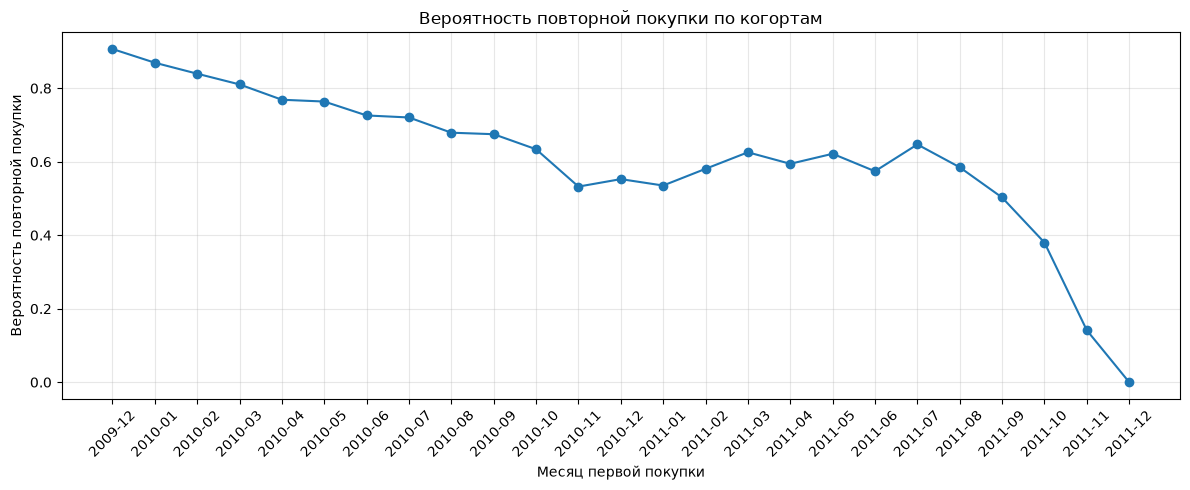

In [38]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(
    cohort_repeat["FirstPurchaseMonth"].astype(str),
    cohort_repeat["RepeatPurchaseProbability"],
    marker="o")
plt.title("Вероятность повторной покупки по когортам")
plt.xlabel("Месяц первой покупки")
plt.ylabel("Вероятность повторной покупки")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 18.4. Повторная покупка в следующем месяце
Вероятность хотя бы одной повторной покупки за весь период зависит от того, сколько времени прошло с первого заказа.
Чтобы сравнивать когорты честнее, отдельно смотрю, купил ли клиент что-то именно в следующем месяце после первой покупки.
Такой показатель оценивает раннее удержание и снижает влияние разной длительности наблюдения для разных когорт.

In [39]:
customer_month_sorted = customer_month.copy()
customer_month_sorted["Month"] = pd.to_datetime(
    customer_month_sorted["Month"].astype(str))
customer_month_sorted = customer_month_sorted.sort_values(
    ["Customer ID", "Month"])
customer_month_sorted["NextPurchaseMonth"] = (
    customer_month_sorted
    .groupby("Customer ID")["Month"]
    .shift(-1))
customer_month_sorted["MonthsUntilNextPurchase"] = ((
        customer_month_sorted["NextPurchaseMonth"].dt.year
        - customer_month_sorted["Month"].dt.year) * 12
    +(
        customer_month_sorted["NextPurchaseMonth"].dt.month
        - customer_month_sorted["Month"].dt.month ))
customer_month_sorted["Returned_Next_Month"] = (
    customer_month_sorted["MonthsUntilNextPurchase"] == 1)
customer_month_sorted[
    ["Customer ID", "Month", "NextPurchaseMonth", "Returned_Next_Month"]
].head(10)

,Customer ID,Month,NextPurchaseMonth,Returned_Next_Month
0,12346.0,2009-12-01,2010-01-01,True
1,12346.0,2010-01-01,2010-03-01,False
2,12346.0,2010-03-01,2010-06-01,False
3,12346.0,2010-06-01,2011-01-01,False
4,12346.0,2011-01-01,NaT,False
5,12347.0,2010-10-01,2010-12-01,False
6,12347.0,2010-12-01,2011-01-01,True
7,12347.0,2011-01-01,2011-04-01,False
8,12347.0,2011-04-01,2011-06-01,False
9,12347.0,2011-06-01,2011-08-01,False


### 18.5. Вероятность покупки в следующем месяце по когортам

Для каждой когорты определим долю новых клиентов, которые совершили покупку в следующем календарном месяце после первой покупки.
Этот показатель позволяет сравнить раннее удержание клиентов между когортами на одинаковом временном горизонте.

In [40]:
first_purchase = customer_month_sorted[
    customer_month_sorted["Month"] ==
    customer_month_sorted.groupby("Customer ID")["Month"].transform("min")
].copy()
cohort_next_month = (
    first_purchase
    .groupby("Month")
    .agg(
        Customers=("Customer ID", "count"),
        ReturnedNextMonth=("Returned_Next_Month", "sum"))
    .reset_index())
cohort_next_month["NextMonthPurchaseProbability"] = (
    cohort_next_month["ReturnedNextMonth"]
    / cohort_next_month["Customers"])
cohort_next_month

,Month,Customers,ReturnedNextMonth,NextMonthPurchaseProbability
0,2009-12-01,955,337,0.352880
1,2010-01-01,383,79,0.206266
2,2010-02-01,374,89,0.237968
3,2010-03-01,443,84,0.189616
4,2010-04-01,294,57,0.193878
5,2010-05-01,254,40,0.157480
6,2010-06-01,270,47,0.174074
7,2010-07-01,186,29,0.155914
8,2010-08-01,162,33,0.203704
9,2010-09-01,243,55,0.226337


### 18.6. Динамика повторной покупки в следующем месяце

Рассмотрим изменение вероятности повторной покупки в следующем месяце для разных когорт.
Последние когорты требуют осторожной интерпретации, поскольку для них период наблюдения ограничен концом датасета.

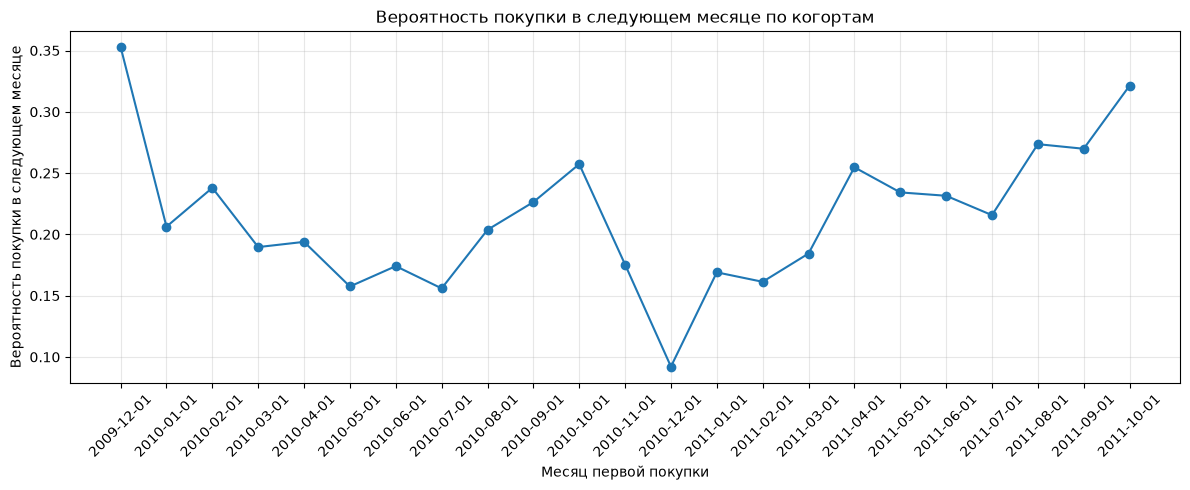

In [41]:
plot_data = cohort_next_month.iloc[:-2].copy()
plt.figure(figsize=(12, 5))
plt.plot(
    plot_data["Month"].astype(str),
    plot_data["NextMonthPurchaseProbability"],
    marker="o"
)
plt.title("Вероятность покупки в следующем месяце по когортам")
plt.xlabel("Месяц первой покупки")
plt.ylabel("Вероятность покупки в следующем месяце")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 18.7. Доверительный интервал вероятности повторной покупки
Полученная вероятность повторной покупки — 69,75%. Но это оценка по нашей выборке.
Посчитаю 95%-ный доверительный интервал для доли клиентов, совершивших повторную покупку. Он покажет диапазон, в котором с заданной уверенностью лежит истинная вероятность для похожей совокупности клиентов.

In [42]:
from statsmodels.stats.proportion import proportion_confint
repeat_count = customer_retention["MadeRepeatPurchase"].sum()
total_customers = len(customer_retention)
ci_low, ci_high = proportion_confint(
    count=repeat_count,
    nobs=total_customers,
    alpha=0.05,
    method="wilson"
)
print(f"Доля клиентов с повторной покупкой: {repeat_count / total_customers:.2%}")
print(f"95%-ный доверительный интервал: {ci_low:.2%} – {ci_high:.2%}")

Доля клиентов с повторной покупкой: 69.75%
95%-ный доверительный интервал: 68.56% – 70.91%


## 19. Проверка различий среднего чека: будни и выходные
Отличается ли средний чек в будни и выходные?
Если разница есть, это пригодится для планирования акций, рекламы и понимания поведения покупателей по дням недели.
Уровень значимости беру α = 0,05.
- **H₀:** средний чек в будни и выходные не отличается.
- **H₁:** средний чек в будни и выходные отличается.
Выручка по заказам может быть скошена и с выбросами, поэтому дополнительно проверю результат критерием Манна–Уитни.

### 19.1. Формирование данных на уровне заказа

Для каждого заказа рассчитаем его общую выручку и день недели.
Один заказ будет представлен одной строкой. Это позволит корректно сравнить распределение среднего чека между будними и выходными днями.

In [43]:
order_analysis = (
    sales_df
    .groupby(["Invoice", "InvoiceDate", "Customer ID"], as_index=False)
    .agg(
        OrderRevenue=("Revenue", "sum"),
        ItemsCount=("Quantity", "sum")
    ))
order_analysis["InvoiceDate"] = pd.to_datetime(
    order_analysis["InvoiceDate"])
order_analysis["Weekday"] = (
    order_analysis["InvoiceDate"].dt.day_name())
order_analysis["DayType"] = np.where(
    order_analysis["InvoiceDate"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday")
order_analysis.head()

,Invoice,InvoiceDate,Customer ID,OrderRevenue,ItemsCount,Weekday,DayType
0,489434,2009-12-01 07:45:00,13085.0,505.30,166,Tuesday,Weekday
1,489435,2009-12-01 07:46:00,13085.0,145.80,60,Tuesday,Weekday
2,489436,2009-12-01 09:06:00,13078.0,630.33,193,Tuesday,Weekday
3,489437,2009-12-01 09:08:00,15362.0,310.75,145,Tuesday,Weekday
4,489438,2009-12-01 09:24:00,18102.0,2286.24,826,Tuesday,Weekday


### 19.2. Описательная статистика среднего чека

Перед проведением статистического теста сравним основные характеристики распределения выручки заказа.
Будем использовать среднее, медиану, стандартное отклонение и количество заказов. Медиана особенно важна, поскольку отдельные очень крупные заказы могут заметно влиять на среднее значение.

In [44]:
order_summary = (
    order_analysis
    .groupby("DayType")["OrderRevenue"]
    .agg(
        Orders="count",
        Mean="mean",
        Median="median",
        Std="std"
    )
    .reset_index())
order_summary

,DayType,Orders,Mean,Median,Std
0,Weekday,32242,493.679449,306.60,1455.587986
1,Weekend,4791,381.176454,281.11,564.759639


### 19.3. Welch t-test
Проверим, отличается ли средний чек в будни и выходные статистически значимо.
Беру Welch t-test, потому что он не требует равенства дисперсий в группах.
- **H₀:** средний чек в будни и выходные одинаков.
- **H₁:** средний чек в будни и выходные отличается.
- **α = 0,05**
Если p-value < 0,05, отвергаем H₀ и считаем различие значимым.

In [45]:
from scipy.stats import ttest_ind
weekday_orders = order_analysis.loc[
    order_analysis["DayType"] == "Weekday",
    "OrderRevenue"]
weekend_orders = order_analysis.loc[
    order_analysis["DayType"] == "Weekend",
    "OrderRevenue"]
t_stat, p_value = ttest_ind(
    weekday_orders,
    weekend_orders,
    equal_var=False)
print(f"t-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.6f}")

t-statistic: 9.782
p-value: 0.000000


### 19.4. Разница среднего чека и 95%-ный доверительный интервал

Рассчитаем разницу между средним чеком в будни и выходные и построим 95%-ный доверительный интервал для этой разницы.
Положительная разница означает, что средний чек в будни выше.

In [46]:
from scipy.stats import t
mean_weekday = weekday_orders.mean()
mean_weekend = weekend_orders.mean()
mean_diff = mean_weekday - mean_weekend
n1 = len(weekday_orders)
n2 = len(weekend_orders)
s1 = weekday_orders.std(ddof=1)
s2 = weekend_orders.std(ddof=1)
se_diff = np.sqrt(
    s1**2 / n1 +
    s2**2 / n2
)
df_welch = (
    (s1**2 / n1 + s2**2 / n2) ** 2/((s1**2 / n1) ** 2 / (n1 - 1)+(s2**2 / n2) ** 2 / (n2 - 1) ))
critical_value = t.ppf(0.975, df_welch)
ci_low = mean_diff - critical_value * se_diff
ci_high = mean_diff + critical_value * se_diff
print(f"Средний чек в будни: £{mean_weekday:.2f}")
print(f"Средний чек в выходные: £{mean_weekend:.2f}")
print(f"Разница средних: £{mean_diff:.2f}")
print(f"95%-ный ДИ: £{ci_low:.2f} – £{ci_high:.2f}")

Средний чек в будни: £493.68
Средний чек в выходные: £381.18
Разница средних: £112.50
95%-ный ДИ: £89.96 – £135.05


### 19.5. Размер эффекта — Cohen's d
Тест показал, что средний чек в будни и выходные различается. Теперь оценим, насколько это различие большое, через Cohen's d.
Это важно, потому что при большом числе наблюдений даже маленькая разница может выйти статистически значимой.
Как читать Cohen's d:
- около 0,2 — эффект небольшой
- около 0,5 — средний
- около 0,8 и выше — большой

In [47]:
pooled_sd = np.sqrt(
    (
        (n1 - 1) * s1**2 +
        (n2 - 1) * s2**2
    )/(n1 + n2 - 2))
cohens_d = mean_diff / pooled_sd
print(f"Cohen's d: {cohens_d:.3f}")

Cohen's d: 0.082


### 19.6. Mann–Whitney U test
Средний чек заметно скошен и есть выбросы: среднее сильно выше медианы. Поэтому дополнительно проверю различие между буднями и выходными непараметрическим критерием Манна–Уитни.
- **H₀:** распределения среднего чека в двух группах не различаются.
- **H₁:** распределения среднего чека различаются.
- **α = 0,05**
Если p-value < 0,05, различие считаем значимым.

In [48]:
from scipy.stats import mannwhitneyu
u_stat, mw_p_value = mannwhitneyu(
    weekday_orders,
    weekend_orders,
    alternative="two-sided")
print(f"U-statistic: {u_stat:.0f}")
print(f"p-value: {mw_p_value:.6f}")

U-statistic: 81034860
p-value: 0.000000


### 19.7. Вывод
Средний чек в будни — £493,68, в выходные — £381,18. Разница £112,50 в пользу будней.
Welch t-test показал значимое различие (t = 9,782; p < 0,001). 95%-ный доверительный интервал для разницы средних — £89,96–£135,05, ноль в него не попадает.
Результат подтверждает и критерий Манна–Уитни (p < 0,001), что важно с учётом скошенности чеков и выбросов.
При этом Cohen's d = 0,082 — эффект очень маленький. То есть различие статистически значимо, но по масштабу на фоне общего разброса чеков оно небольшое.
По бизнесу это значит: в наших данных заказы в будни в среднем дороже, но сам по себе день недели вряд ли сильно определяет величину заказа. Для решений стоит ещё смотреть количество заказов, состав корзины и сезонность.

### 19.8. Распределение среднего чека

Для визуального сравнения групп посмотрим на распределение среднего чека 
в будние и выходные дни. Boxplot позволяет сравнить медиану, разброс 
и наличие выбросов.

<Figure size 800x500 with 0 Axes>

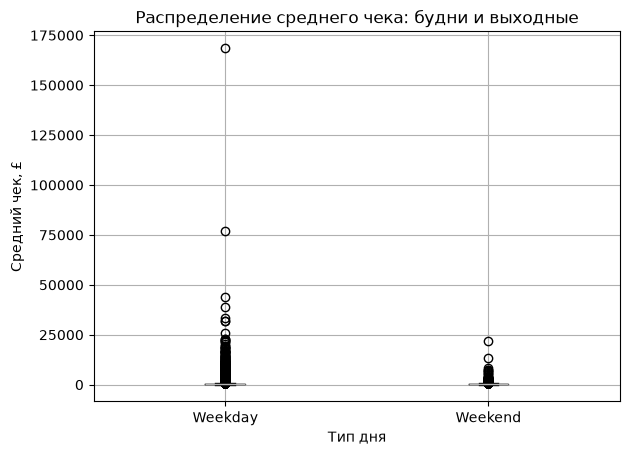

In [49]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
order_analysis.boxplot(
    column="OrderRevenue",
    by="DayType"
)
plt.title("Распределение среднего чека: будни и выходные")
plt.suptitle("")
plt.xlabel("Тип дня")
plt.ylabel("Средний чек, £")
plt.tight_layout()
plt.show()

### 19.9. Количество заказов по типу дня

Разница в среднем чеке не показывает, как распределяется общий объём заказов. 
Поэтому дополнительно сравним количество заказов в будние и выходные дни.

In [50]:
orders_by_day_type = (
    order_analysis
    .groupby("DayType")
    .agg(
        Orders=("Invoice", "nunique"),
        TotalRevenue=("OrderRevenue", "sum"),
        AverageOrderValue=("OrderRevenue", "mean") )
    .reset_index())
orders_by_day_type

,DayType,Orders,TotalRevenue,AverageOrderValue
0,Weekday,32191,1.591721e+07,493.679449
1,Weekend,4778,1.826216e+06,381.176454


### 19.10. Доля заказов и выручки по типу дня

Дополнительно сравним долю заказов и выручки, приходящуюся на будние и выходные дни.
Это позволяет оценить не только различие среднего чека, но и вклад каждого типа дня в общий объём продаж.

In [51]:
orders_by_day_type["OrderShare"] = (
    orders_by_day_type["Orders"]
    / orders_by_day_type["Orders"].sum())
orders_by_day_type["RevenueShare"] = (
    orders_by_day_type["TotalRevenue"]
    / orders_by_day_type["TotalRevenue"].sum())
orders_by_day_type

,DayType,Orders,TotalRevenue,AverageOrderValue,OrderShare,RevenueShare
0,Weekday,32191,1.591721e+07,493.679449,0.870757,0.897076
1,Weekend,4778,1.826216e+06,381.176454,0.129243,0.102924


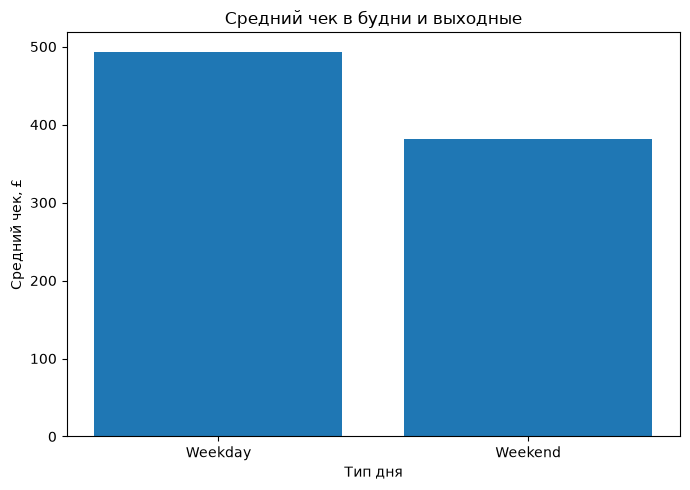

In [52]:
plt.figure(figsize=(7, 5))
plt.bar(
    orders_by_day_type["DayType"],
    orders_by_day_type["AverageOrderValue"])
plt.title("Средний чек в будни и выходные")
plt.xlabel("Тип дня")
plt.ylabel("Средний чек, £")
plt.tight_layout()
plt.show()

### 19.11. Итоговый вывод
В будни средний чек — £493,68, в выходные — £381,18. Разница £112,50 в пользу будней. 95%-ный доверительный интервал для разницы — £89,96–£135,05.
Welch t-test показал значимое различие (t = 9,782; p < 0,001). Результат подтверждает и критерий Манна–Уитни (p < 0,001).
При этом Cohen's d = 0,082 — эффект очень маленький на фоне общего разброса чеков. То есть различие значимо статистически, но по практике небольшое.
Будни дают и основную часть продаж: 87,1% заказов и 89,7% выручки. На выходные — 12,9% заказов и 10,3% выручки.
В итоге в наших данных будни — это и более высокий средний чек, и заметно больший объём заказов. Но сам день недели вряд ли сильно определяет размер заказа, потому что эффект маленький.
Для бизнеса это повод отдельно смотреть поведение клиентов и состав заказов в будни и выходные, но менять стратегию только из-за дня недели — рано.

## 20. Сравнение клиентских групп
### 20.1. Формирование клиентских групп
Чтобы сравнить поведение клиентов, разделю их по числу заказов за весь период:
- **1 заказ** — разовые покупатели;
- **2–3 заказа** — периодически возвращающиеся;
- **4 и более заказов** — активные клиенты.
Сравнивать буду по общей выручке от клиента за весь период.

**Бизнес-вопрос:** отличается ли средняя выручка на клиента между этими группами?
Для проверки различий между несколькими независимыми группами дальше возьму однофакторный ANOVA.

In [53]:
customer_analysis_df = (
    sales_df
    .groupby("Customer ID")
    .agg(
        Orders=("Invoice", "nunique"),
        Revenue=("Revenue", "sum"),
        AverageOrderValue=("Revenue", lambda x: x.sum() / sales_df.loc[x.index, "Invoice"].nunique()))
    .reset_index())
customer_analysis_df.head()

,Customer ID,Orders,Revenue,AverageOrderValue
0,12346.0,12,77556.46,6463.038333
1,12347.0,8,5633.32,704.165000
2,12348.0,5,2019.40,403.880000
3,12349.0,4,4428.69,1107.172500
4,12350.0,1,334.40,334.400000


In [54]:
customer_analysis_df["CustomerGroup"] = pd.cut(
    customer_analysis_df["Orders"],
    bins=[0, 1, 3, float("inf")],
    labels=[
        "1 order",
        "2–3 orders",
        "4+ orders"
    ])
customer_analysis_df["CustomerGroup"].value_counts().sort_index()

CustomerGroup
1 order       1623
2–3 orders    1608
4+ orders     2647
Name: count, dtype: int64

In [55]:
group_summary = (
    customer_analysis_df
    .groupby("CustomerGroup", observed=True)
    .agg(
        Customers=("Customer ID", "count"),
        MeanRevenue=("Revenue", "mean"),
        MedianRevenue=("Revenue", "median"),
        StdRevenue=("Revenue", "std") )
    .reset_index())
group_summary

,CustomerGroup,Customers,MeanRevenue,MedianRevenue,StdRevenue
0,1 order,1623,350.076298,232.480,600.949596
1,2–3 orders,1608,1009.077129,640.945,4544.851339
2,4+ orders,2647,5875.579646,2470.670,21322.955479


### 20.3. Однофакторный ANOVA
Проверим, отличается ли средняя выручка на клиента между тремя группами по числу заказов.
- **H₀:** средняя выручка одинакова во всех трёх группах.
- **H₁:** хотя бы в одной группе средняя выручка отличается.
- **α = 0,05**
Беру однофакторный ANOVA, потому что сравниваю средние трёх независимых групп.
Если p-value < 0,05, нулевую гипотезу отвергаем. Это покажет, что различие между группами есть, но не покажет, какие именно группы отличаются.

In [56]:
from scipy.stats import f_oneway

group_1 = customer_analysis_df.loc[
    customer_analysis_df["CustomerGroup"] == "1 order",
    "Revenue"]
group_2 = customer_analysis_df.loc[
    customer_analysis_df["CustomerGroup"] == "2–3 orders",
    "Revenue"]
group_3 = customer_analysis_df.loc[
    customer_analysis_df["CustomerGroup"] == "4+ orders",
    "Revenue"]
f_stat, anova_p_value = f_oneway(
    group_1,
    group_2,
    group_3)
print(f"F-statistic: {f_stat:.3f}")
print(f"p-value: {anova_p_value:.6f}")

F-statistic: 94.185
p-value: 0.000000


### 20.4. Размер эффекта — η²
После ANOVA оценим размер различий через η² (eta squared).
Он показывает, какую долю вариации выручки клиентов можно связать с группой по числу заказов.
Ориентиры для интерпретации:
- около 0,01 — эффект небольшой;
- около 0,06 — средний;
- около 0,14 и выше — большой.
Так видно не только значимость различий, но и их практический масштаб.

In [57]:
all_revenue = pd.concat(
    [group_1, group_2, group_3],
    ignore_index=True
)
grand_mean = all_revenue.mean()
ss_between = (
    len(group_1) * (group_1.mean() - grand_mean) ** 2
    + len(group_2) * (group_2.mean() - grand_mean) ** 2
    + len(group_3) * (group_3.mean() - grand_mean) ** 2
)

ss_total = (
    (all_revenue - grand_mean) ** 2
).sum()
eta_squared = ss_between / ss_total
print(f"η²: {eta_squared:.3f}")

η²: 0.031


### 20.5. Попарные сравнения — Tukey HSD
ANOVA показал, что различия между группами есть, но не сказал, между какими именно.
Для этого делаю пост-хок тест Tukey HSD с α = 0,05.
Он сравнивает каждую пару групп и показывает:
- разницу средних значений выручки;
- значимость различий;
- доверительный интервал для разницы.

In [58]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(
    endog=customer_analysis_df["Revenue"],
    groups=customer_analysis_df["CustomerGroup"],
    alpha=0.05
)
print(tukey)

       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
  group1     group2    meandiff p-adj    lower     upper   reject
-----------------------------------------------------------------
   1 order 2–3 orders  659.0008 0.4004 -537.8226 1855.8242  False
   1 order  4+ orders 5525.5033    0.0 4453.1409 6597.8658   True
2–3 orders  4+ orders 4866.5025    0.0  3791.044  5941.961   True
-----------------------------------------------------------------


### 20.6. Итоговый вывод
Средняя выручка значимо различается между группами по числу заказов (ANOVA: F = 94,185; p < 0,001).
Но эффект небольшой: η² = 0,031 — группа объясняет всего ~3,1% разброса выручки.
Tukey HSD: между 1 заказом и 2–3 значимого различия нет (p = 0,400). А у 4+ заказов средняя выручка значимо выше и против 1 заказа, и против 2–3 (p < 0,001).
Средняя выручка:
- 1 заказ — £350,08
- 2–3 заказа — £1 009,08
- 4+ заказов — £5 875,58
Главный скачок — при переходе в группу 4+ заказов. Но само число заказов объясняет лишь малую часть разброса выручки.
По бизнесу это подтверждает ценность активных клиентов: их выручка заметно выше. Дальше стоит смотреть, чем они отличаются от остальных.

## 21. Корреляционный анализ клиентского поведения

### 21.1. Подготовка данных
Для корреляционного анализа беру данные на уровне клиента.
Смотрю, как общая выручка клиента связана с основными характеристиками поведения:
- количество заказов
- средний чек
- количество уникальных товаров
- длительность клиентского периода
- количество дней с момента последней покупки
Использую Pearson и Spearman. Pearson — линейная связь, Spearman — монотонная, и он менее чувствителен к выбросам и ненормальному распределению.

In [59]:
customer_corr = (
    sales_df
    .groupby("Customer ID")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("Invoice", "nunique"),
        AverageOrderValue=("Revenue", 
                           lambda x: x.sum() / sales_df.loc[x.index, "Invoice"].nunique()),
        UniqueProducts=("StockCode", "nunique"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
    .reset_index())
customer_corr["CustomerLifetimeDays"] = (
    customer_corr["LastPurchase"] - customer_corr["FirstPurchase"]
).dt.days
analysis_columns = [
    "Revenue",
    "Orders",
    "AverageOrderValue",
    "UniqueProducts",
    "CustomerLifetimeDays"]
customer_corr[analysis_columns].describe()

,Revenue,Orders,AverageOrderValue,UniqueProducts,CustomerLifetimeDays
count,5878.000000,5878.000000,5878.000000,5878.000000,5878.000000
mean,3018.616737,6.289384,391.726538,81.989112,273.022457
std,14737.731040,13.009406,1215.071054,116.484552,258.807591
min,2.950000,1.000000,2.950000,1.000000,0.000000
25%,348.762500,1.000000,181.652500,19.000000,0.000000
50%,898.915000,3.000000,285.070500,45.000000,220.500000
75%,2307.090000,7.000000,420.570000,103.000000,511.000000
max,608821.650000,398.000000,84236.250000,2550.000000,738.000000


### 21.2. Коэффициенты корреляции
Считаю Pearson и Spearman для основных показателей клиентского поведения.
Pearson показывает силу линейной связи, Spearman — монотонную по рангам и меньше реагирует на выбросы и сильную асимметрию.
Особое внимание — связи этих показателей с общей выручкой клиента.

In [60]:
from scipy.stats import pearsonr, spearmanr
correlation_columns = [
    "Revenue",
    "Orders",
    "AverageOrderValue",
    "UniqueProducts",
    "CustomerLifetimeDays"]
pearson_corr = customer_corr[correlation_columns].corr(method="pearson")
spearman_corr = customer_corr[correlation_columns].corr(method="spearman")
print("Pearson correlation:")
display(pearson_corr.round(3))
print("\nSpearman correlation:")
display(spearman_corr.round(3))

Pearson correlation:


,Revenue,Orders,AverageOrderValue,UniqueProducts,CustomerLifetimeDays
Revenue,1.000,0.630,0.267,0.407,0.213
Orders,0.630,1.000,0.035,0.693,0.442
AverageOrderValue,0.267,0.035,1.000,0.052,0.017
UniqueProducts,0.407,0.693,0.052,1.000,0.499
CustomerLifetimeDays,0.213,0.442,0.017,0.499,1.000



Spearman correlation:


,Revenue,Orders,AverageOrderValue,UniqueProducts,CustomerLifetimeDays
Revenue,1.000,0.859,0.654,0.771,0.764
Orders,0.859,1.000,0.215,0.724,0.882
AverageOrderValue,0.654,0.215,1.000,0.426,0.211
UniqueProducts,0.771,0.724,0.426,1.000,0.661
CustomerLifetimeDays,0.764,0.882,0.211,0.661,1.000


### 21.3. Проверка статистической значимости корреляций
Сильная корреляция сама по себе ещё не значит, что связь статистически значима.
Проверю корреляции общей выручки с основными характеристиками клиента через Pearson и Spearman. Для каждой связи получу коэффициент корреляции и p-value.
Уровень значимости — α = 0,05.

In [61]:
from scipy.stats import pearsonr, spearmanr
target = "Revenue"
features = [
    "Orders",
    "AverageOrderValue",
    "UniqueProducts",
    "CustomerLifetimeDays"]
results = []
for feature in features:
    pearson_r, pearson_p = pearsonr(
        customer_corr[target],
        customer_corr[feature] )
    spearman_r, spearman_p = spearmanr(
        customer_corr[target],
        customer_corr[feature] ) 
    results.append({
        "Feature": feature,
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_r": spearman_r,
        "Spearman_p": spearman_p
    })
correlation_results = pd.DataFrame(results)
correlation_results.round(4)

,Feature,Pearson_r,Pearson_p,Spearman_r,Spearman_p
0,Orders,0.6296,0.0,0.8594,0.0
1,AverageOrderValue,0.2671,0.0,0.6536,0.0
2,UniqueProducts,0.4070,0.0,0.7713,0.0
3,CustomerLifetimeDays,0.2134,0.0,0.7636,0.0


### 21.4. Итоговый вывод
Все показатели значимо и положительно связаны с общей выручкой клиента (p < 0,001).
Сильнее всего — с числом заказов: Pearson = 0,630, Spearman = 0,859.
Дальше идут уникальные товары (Pearson = 0,407; Spearman = 0,771) и длительность клиентского периода (Pearson = 0,213; Spearman = 0,764).
Средний чек связан слабее по Pearson (0,267), но выше по Spearman (0,654).
Разрыв между Pearson и Spearman особенно большой для CustomerLifetimeDays и AverageOrderValue. Причина — сильная асимметрия и клиенты с экстремальными значениями. Так что тут надёжнее смотреть на Spearman.
По бизнесу: выручка растёт вместе с частотой покупок и широтой ассортимента. Долгое взаимодействие с компанией тоже связано с большей выручкой.
Но это не значит, что число заказов само по себе тянет выручку вверх — оба показателя могут зависеть от чего-то третьего.

## 22. Логистическая регрессия
### 22.1. Постановка задачи
Проверим, какие характеристики клиента связаны с вероятностью повторной покупки.
Целевая переменная:
-  1 — клиент купил повторно
-  0 — больше не покупал
Признаки беру из первой покупки клиента, чтобы не тащить утечку из будущего.
Логистическая регрессия покажет направление и силу связи между характеристиками клиента и вероятностью повторной покупки.

In [62]:
first_purchase = (
    sales_df
    .sort_values("InvoiceDate")
    .groupby("Customer ID")
    .first()
    .reset_index())
first_purchase_features = (
    sales_df
    .groupby(["Customer ID", "Invoice"])
    .agg(
        OrderRevenue=("Revenue", "sum"),
        ItemsCount=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"))
    .reset_index())
first_order = (
    first_purchase[["Customer ID", "Invoice"]]
    .merge(
        first_purchase_features,
        on=["Customer ID", "Invoice"],
        how="left"
    ))
logit_data = first_order.merge(
    customer_retention[["Customer ID", "MadeRepeatPurchase"]],
    on="Customer ID",
    how="inner")
logit_data.head()

,Customer ID,Invoice,OrderRevenue,ItemsCount,UniqueProducts,MadeRepeatPurchase
0,12346.0,491725,45.00,10,1,True
1,12347.0,529924,611.53,509,40,True
2,12348.0,524140,222.16,373,20,True
3,12349.0,506394,1068.52,473,46,True
4,12350.0,543037,334.40,197,17,False


### 22.2. Баланс целевой переменной

Перед построением модели проверим распределение целевой переменной.
Это необходимо, чтобы понять, насколько сбалансированы группы клиентов 
с повторной и без повторной покупки.

In [63]:
target_distribution = (
    logit_data["MadeRepeatPurchase"]
    .value_counts()
    .rename(index={
        False: "No repeat purchase",
        True: "Repeat purchase"
    })
    .to_frame("Customers"))
target_distribution["Share"] = (
    target_distribution["Customers"]
    / target_distribution["Customers"].sum()
)
target_distribution

,Customers,Share
MadeRepeatPurchase,,
Repeat purchase,4100,0.697516
No repeat purchase,1778,0.302484


### 22.3. Построение логистической регрессии
В модель беру характеристики первого заказа клиента:
- OrderRevenue — выручка первого заказа;
- ItemsCount — количество единиц товара в первом заказе;
- UniqueProducts — количество уникальных товаров в первом заказе.
Целевая — факт повторной покупки.
Распределения по первому заказу скошены, поэтому перед моделью делаю логарифмическое преобразование log1p — так экстремально большие значения меньше мешают.
Коэффициенты оцениваю через логистическую регрессию statsmodels — так получаю стандартные ошибки, p-value и доверительные интервалы.

In [64]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
model_features = [
    "OrderRevenue",
    "ItemsCount",
    "UniqueProducts"]
X = logit_data[model_features].copy()
y = logit_data["MadeRepeatPurchase"].astype(int)
X_log = np.log1p(X)
X_scaled = (X_log - X_log.mean()) / X_log.std()
X_scaled = sm.add_constant(X_scaled)
logit_model = sm.Logit(y, X_scaled).fit()
print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.603481
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:     MadeRepeatPurchase   No. Observations:                 5878
Model:                          Logit   Df Residuals:                     5874
Method:                           MLE   Df Model:                            3
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                 0.01545
Time:                        20:06:59   Log-Likelihood:                -3547.3
converged:                       True   LL-Null:                       -3602.9
Covariance Type:            nonrobust   LLR p-value:                 5.579e-24
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.8522      0.029     29.555      0.000       0.796       0.909
OrderRevenue     

### 22.4. Интерпретация коэффициентов
Коэффициенты логистической регрессии показывают, куда и как связан признак с вероятностью повторной покупки. Чтобы читать было проще, переведу их в odds ratio.
Odds ratio > 1 — связь положительная, < 1 — отрицательная.
Ещё посчитаю 95%-ные доверительные интервалы для odds ratio.

In [65]:
params = logit_model.params
conf = logit_model.conf_int()
odds_ratios = np.exp(params)
ci_lower = np.exp(conf[0])
ci_upper = np.exp(conf[1])
logit_results = pd.DataFrame({
    "Coefficient": params,
    "StdError": logit_model.bse,
    "PValue": logit_model.pvalues,
    "OddsRatio": odds_ratios,
    "CI_lower": ci_lower,
    "CI_upper": ci_upper
})
logit_results.round(4)

,Coefficient,StdError,PValue,OddsRatio,CI_lower,CI_upper
const,0.8522,0.0288,0.0000,2.3448,2.2159,2.4811
OrderRevenue,0.1880,0.0483,0.0001,1.2068,1.0979,1.3266
ItemsCount,0.0475,0.0486,0.3284,1.0486,0.9534,1.1534
UniqueProducts,0.1040,0.0361,0.0040,1.1096,1.0338,1.1910


#### 22.5. Итоговый вывод
Модель в целом значима (LLR p < 0,001), но Pseudo R² = 0,015 — маловато. Одних характеристик первой покупки не хватает, чтобы нормально объяснить повторную покупку.
Сильнее всего с возвратом связана выручка первого заказа: odds ratio = 1,207 (95% ДИ: 1,098–1,327; p < 0,001). Ещё значимо число уникальных товаров в первом заказе: odds ratio = 1,110 (95% ДИ: 1,034–1,191; p = 0,004).
А количество единиц товара — мимо (p = 0,328), и интервал (0,953–1,153) включает 1.
В общем, кто первым заказом взял больше и разнообразнее — тот чаще возвращается. Но это связь, не причина. Не факт, что большой заказ сам по себе тянет клиента назад.
По делу: уже по первой покупке можно прикинуть, кто вероятнее вернётся. Но для точного прогноза нужны и другие данные по клиенту.

## 23. Общий вывод

**Повторные покупки — ключевой драйвер выручки.**
Большая часть клиентов возвращается, и в среднем они приносят больше выручки и делают больше заказов.

**Число заказов объясняет не всё.**
Разницу в выручке между клиентами также связывают количество уникальных товаров и длительность взаимодействия с компанией.

**Различия видны уже по первой покупке.**
Чем выше выручка первого заказа и чем больше в нём разных товаров, тем выше вероятность, что клиент вернётся. А количество купленных единиц товара такой связи не показало.

**Средний чек: будни и выходные.**
В будни чек выше, но разница небольшая на фоне общего разброса — серьёзных выводов делать не стоит.

**Что дальше.**
Главное направление — работа с повторными покупками. Возвращающиеся клиенты уже дают значительную часть выручки, поэтому важно понимать, что влияет на их возвращение и какие характеристики первой покупки с этим связаны.